In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score

In [49]:
df_raw = pd.read_csv("data/telescope_data.csv")
df = pd.DataFrame()
df = df_raw.drop(columns=df_raw.columns[0], inplace=False)
col_names = ["fLength","fWidth","fSize","fConc","fConc1","fAsym","fM3Long","fM3Trans","fAlpha","fDist","class"]
df.columns = col_names
df['class'] = label_binarize(df['class'], classes=['g', 'h']).ravel()

In [50]:
lowE = df[df["fSize"] < 3.0]
X = lowE.drop(columns=["class","fSize"],inplace=False)
class_labels = lowE["class"]

In [42]:
gamma_flag = (class_labels == 0)
gamma_lowE = lowE[gamma_flag]
cosmic_lowE = lowE[~gamma_flag]

def plot_pdf(gamma:pd.DataFrame, cosmic:pd.DataFrame ,nbins:int, xlabel:str, scale="linear") -> None:
    title = f"PDF of {xlabel}"
    plt.hist(gamma,bins=nbins,density=True, label="Gamma")
    plt.hist(cosmic,bins=nbins,alpha=0.5 ,density=True, label="Cosmic")
    #plt.xlim(llim,hlim)
    plt.xlabel(xlabel)
    plt.ylabel("Probability Density")
    plt.title(title)
    plt.yscale(scale)
    plt.legend()
    plt.show()


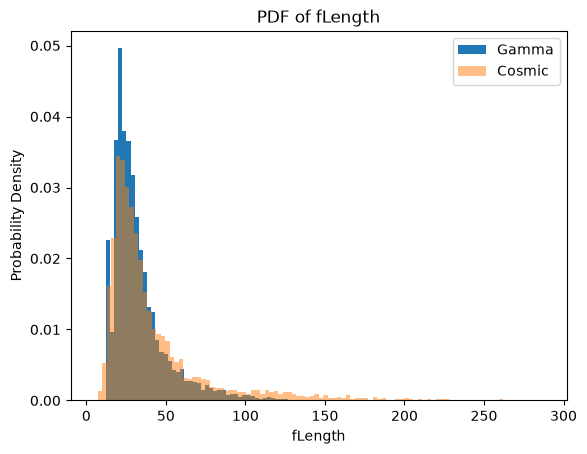

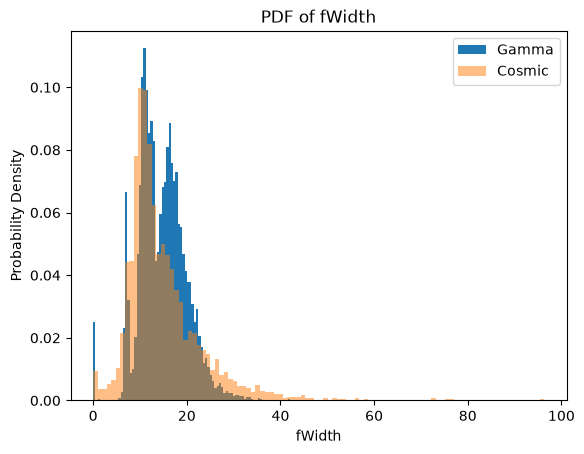

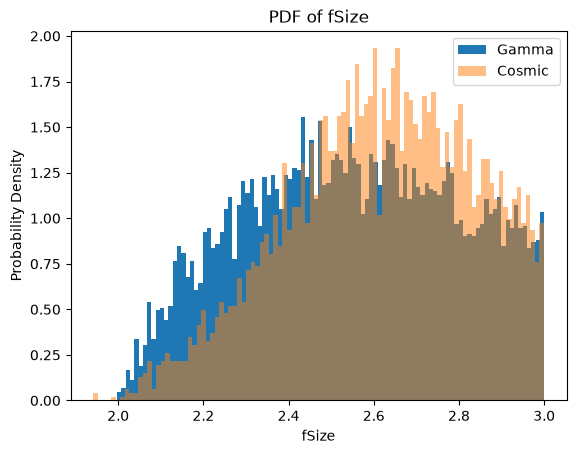

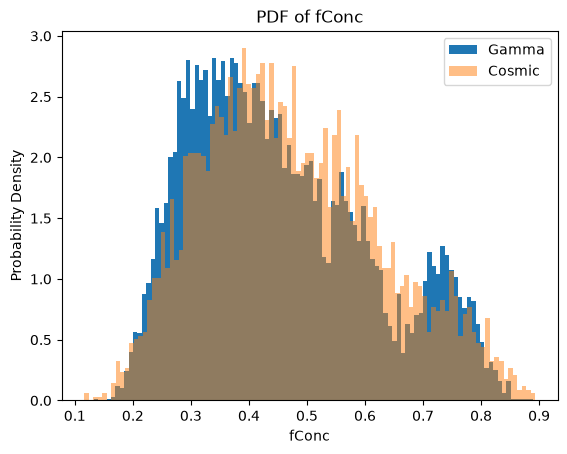

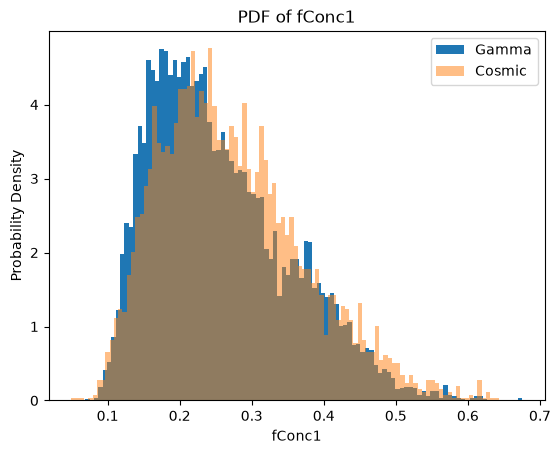

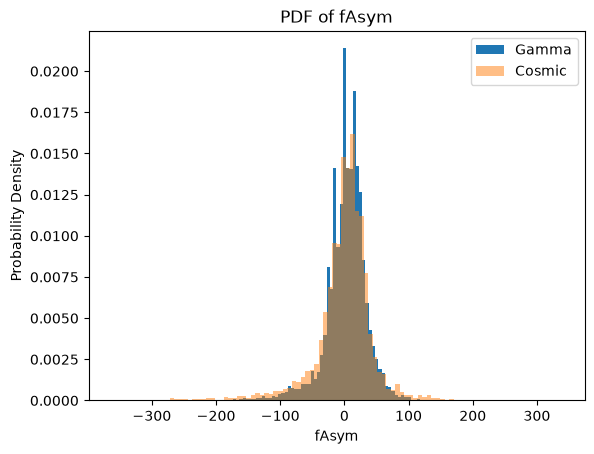

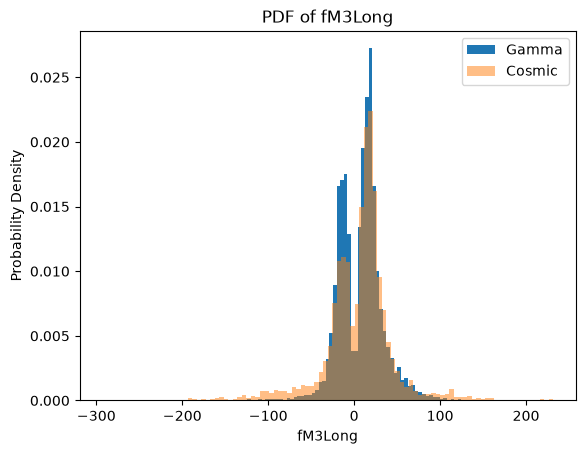

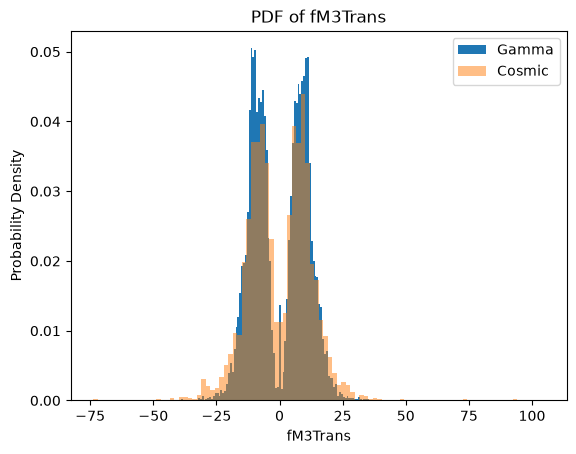

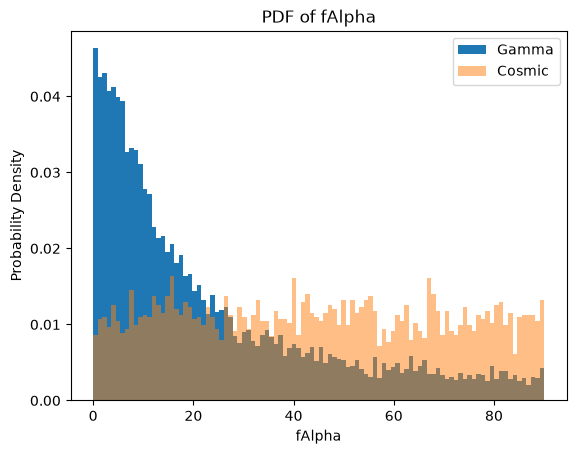

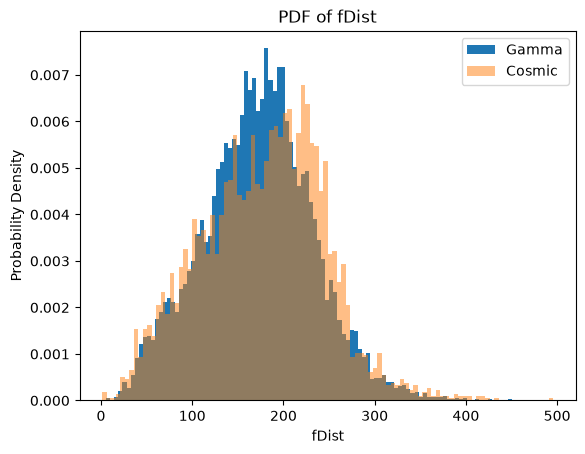

In [43]:
for col_name in lowE.columns[:-1]:
    plot_pdf(gamma_lowE[col_name], cosmic_lowE[col_name], 100, col_name)

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, class_labels, test_size=0.2, random_state=1, stratify=class_labels
)

I chose to do 20% for the test size arbitrarily. I chose to do stratify as I wanted to preserve the proportion of class labels in training and testing. Gamma occurs almost twice as much as Cosmic. I chose the random_state for it to be more reporoducible.

In [69]:
for md in [6,8,10,12,16]:
    D_tree = DecisionTreeClassifier(max_depth=md,min_samples_leaf=64,random_state=0)
    D_tree.fit(X_train,y_train)
    y_predict = D_tree.predict(X_test)
    y_pre_train = D_tree.predict(X_train)
    y_prob = D_tree.predict_proba(X_test)[:, 0]
    auc = roc_auc_score(1-y_test, y_prob)
    
    print("Accuracy score on the test data: {:.3f}".format(accuracy_score(y_test,y_predict)))
    print("Accuracy score on the training data: {:.3f}".format(accuracy_score(y_train,y_pre_train)))
    print(f"AUC score on test data with max_depth {md}: {auc :.3f} \n")

Accuracy score on the test data: 0.779
Accuracy score on the training data: 0.791
AUC score on test data with max_depth 6: 0.822 

Accuracy score on the test data: 0.779
Accuracy score on the training data: 0.801
AUC score on test data with max_depth 8: 0.823 

Accuracy score on the test data: 0.780
Accuracy score on the training data: 0.803
AUC score on test data with max_depth 10: 0.822 

Accuracy score on the test data: 0.780
Accuracy score on the training data: 0.803
AUC score on test data with max_depth 12: 0.819 

Accuracy score on the test data: 0.780
Accuracy score on the training data: 0.803
AUC score on test data with max_depth 16: 0.819 

